# PCA Analysis of Dissolved Oxygen

This notebook performs Principal Component Analysis (PCA) on the spatially interpolated DO data from `09_Spatial_Interpolation_v2.ipynb`.

**Objective**: Identify dominant spatial and temporal patterns in DO variability across stations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import sys
from pathlib import Path

# Ensure local scripts are importable
project_root = Path("../../").resolve()
sys.path.append(str(project_root))

from scripts.paths import ProjectPaths

# Configure plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [2]:
# Parameters
subset_dir = str(ProjectPaths.get_subset_dir('Summer', 'bottom'))  # default subset

## 1. Load Interpolated Data

In [3]:
# Load interpolated DO data from subset directory
from pathlib import Path
subset_path = Path(subset_dir)

interpolated_do_df = pd.read_csv(subset_path / "interpolated_do_df.csv", index_col=0)
interpolated_do_df.index = interpolated_do_df.index.astype(str).str.zfill(8)

print(f"Loaded from: {subset_path}")
print(f"Interpolated DO shape: {interpolated_do_df.shape}")
print(f"Remaining NaN values: {interpolated_do_df.isna().sum().sum()}")
interpolated_do_df.head()


Loaded from: /home/reyha/SIS_Analysis_WSL/data/processed/seasonal/summer_bottom
Interpolated DO shape: (124, 41)
Remaining NaN values: 26


,1982,1984,1985,1986,1987,1988,1989,1990,1991,1992,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
zettaicode,,,,,,,,,,,,,,,,,,,,,
00000272,4.0,1.1,1.9,2.1,0.800000,2.9,2.1,1.5,0.9,1.2,...,NaN,NaN,0.600000,0.700000,1.1,1.1,0.8,1.1,NaN,1.4
00000275,1.1,1.5,0.7,3.1,3.154227,1.1,1.4,0.3,1.1,1.0,...,4.374343,0.6,2.759456,2.123493,0.6,0.8,2.3,0.6,4.597053,1.2
00002725,5.6,4.8,3.9,9.5,6.200000,5.0,5.5,5.9,7.2,3.0,...,6.200000,6.1,5.900000,2.900000,6.6,6.6,3.1,6.4,6.500000,6.8
00002737,6.8,5.4,5.1,6.6,6.000000,4.7,6.0,4.6,4.9,7.5,...,6.500000,5.5,6.000000,6.200000,6.1,7.6,6.9,5.3,4.900000,6.3
00002744,6.6,3.6,4.8,5.8,5.800000,5.5,5.6,6.4,5.3,4.3,...,5.900000,6.3,5.800000,6.700000,6.2,6.5,6.0,6.1,6.400000,7.2


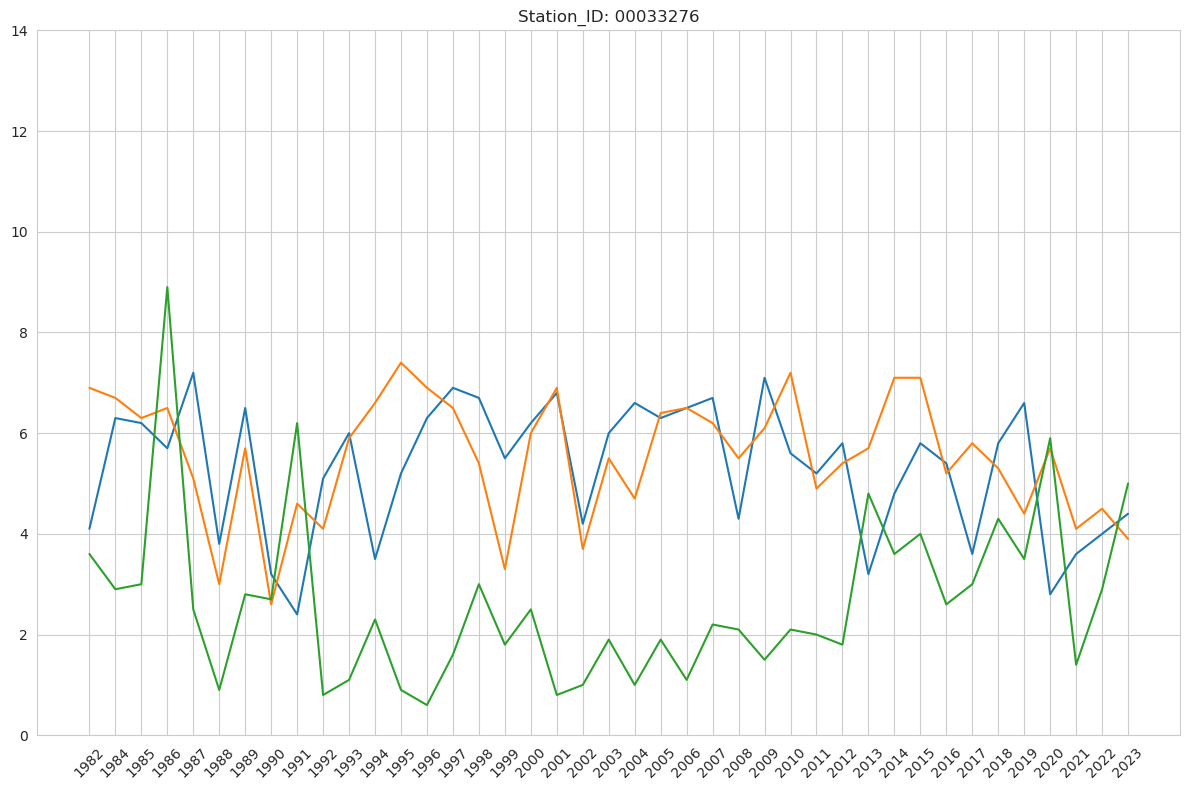

In [4]:
station_id = "00033276"
plot_timeseries = interpolated_do_df.loc[station_id]

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
ax.plot(plot_timeseries)
ax.plot(interpolated_do_df.loc['00037263'])
ax.plot(interpolated_do_df.loc['00002823'])
ax.set_title(f"Station_ID: {station_id}")
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(0, 14)

plt.tight_layout()
plt.show()

## 2. Prepare Data for PCA

PCA requires complete data (no NaN). We drop any stations still containing missing values after interpolation.

(edit) The previous filtering filters out the stations which has even 1 missing stations. This ended up filtering out 24 stations. However, the dropped stations only contains 1-2 years of missing data. So this time I will try to fill in those missing data with synthetic data using *imputation* (the column mean).  

In [5]:
# Fill remaining NaN values with column means (annual mean DO across all stations).
# After spatial interpolation, only ~0.5% of cells remain missing (26 out of 5084).
# Column-mean imputation is the most neutral choice: it adds no station-specific 
# signal, avoiding artificial inflation of any station's eigenvector loading.
nan_count = interpolated_do_df.isna().sum().sum()
total_cells = interpolated_do_df.shape[0] * interpolated_do_df.shape[1]
print(f"Remaining NaN cells before imputation: {nan_count} / {total_cells} ({nan_count/total_cells*100:.2f}%)")

pca_ready_df = interpolated_do_df.fillna(interpolated_do_df.mean(axis=0))

print(f"Stations retained for PCA: {len(pca_ready_df)} / {len(interpolated_do_df)}")
print(f"Years: {len(pca_ready_df.columns)}")

# Transpose: rows = years (samples), columns = stations (features)
data_matrix = pca_ready_df.T
print(f"\nData matrix shape (years x stations): {data_matrix.shape}")

Remaining NaN cells before imputation: 26 / 5084 (0.51%)
Stations retained for PCA: 124 / 124
Years: 41

Data matrix shape (years x stations): (41, 124)


Number of dropped stations: 0


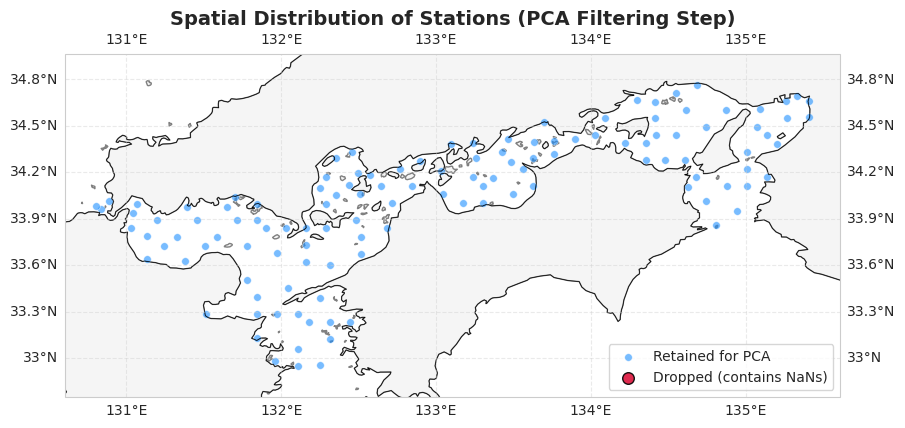

In [6]:
import geopandas as gpd
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Change this part in Step 1:

# 1. Identify dropped vs retained stations
# Dropped stations are those that were in the original set but are NOT in the final set
dropped_ids = interpolated_do_df.index.difference(pca_ready_df.index).tolist()
retained_ids = pca_ready_df.index.tolist()

# This mask is for the dataframe you are actually the analysis on
dropped_mask = pca_ready_df.isna().any(axis=1) 

# Create the filtered dataframe of dropped stations for inspection
dropped_stations_df = interpolated_do_df[dropped_mask]

dropped_ids = interpolated_do_df.index[dropped_mask].tolist()
retained_ids = pca_ready_df.index.tolist()

print(f"Number of dropped stations: {len(dropped_ids)}")
if len(dropped_ids) > 0:
    print(f"Sample dropped IDs: {dropped_ids[:5]}...")

# 2. Load station coordinates from merged GeoDataFrame
gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)
gdf_unique_stations = gdf.drop_duplicates(subset='zettaicode')[['zettaicode', 'geometry']].copy()
gdf_unique_stations['zettaicode'] = gdf_unique_stations['zettaicode'].astype(str)

# 3. Prepare data for mapping
retained_df = pd.DataFrame({'zettaicode': retained_ids, 'status': 'Retained'})
dropped_df = pd.DataFrame({'zettaicode': dropped_ids, 'status': 'Dropped'})
status_df = pd.concat([retained_df, dropped_df])

map_data = gdf_unique_stations.merge(status_df, on='zettaicode', how='inner')

# 4. Mapping with Cartopy
pad = 0.2
min_lon, min_lat, max_lon, max_lat = map_data.total_bounds
extent = [min_lon - pad, max_lon + pad, min_lat - pad, max_lat + pad]

fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(extent, crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, facecolor='whitesmoke', edgecolor='gray')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4)

# Plot retained stations
retained_pts = map_data[map_data['status'] == 'Retained']
ax.scatter(
    retained_pts.geometry.x,
    retained_pts.geometry.y,
    color='dodgerblue', s=30, label='Retained for PCA', alpha=0.6,
    edgecolor='white', linewidth=0.5, transform=ccrs.PlateCarree()
)

# Plot dropped stations
dropped_pts = map_data[map_data['status'] == 'Dropped']
ax.scatter(
    dropped_pts.geometry.x,
    dropped_pts.geometry.y,
    color='crimson', s=70, label='Dropped (contains NaNs)', alpha=0.9,
    edgecolor='black', linewidth=1.0, transform=ccrs.PlateCarree()
)

plt.title('Spatial Distribution of Stations (PCA Filtering Step)', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', frameon=True, facecolor='white')
plt.show()


In [7]:
# --- CONFIGURATION ---
# Set to True to use Standardized data (mean=0, std=1)
# Set to False to use Raw data (preserving magnitude)
USE_STANDARDIZED_DATA = False 

# 1. Standardize the data (we compute this always, but only use if selected)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data_matrix)

# 2. Select the dataset for PCA
if USE_STANDARDIZED_DATA:
    pca_input_data = scaled_data
    print(f"--> MODE: Using STANDARDIZED Data for PCA.")
    print("    (Focuses on correlation patterns; gives rare stations equal weight)")
else:
    pca_input_data = data_matrix
    print(f"--> MODE: Using RAW Data for PCA.")
    print("    (Preserves absolute magnitude variations)")

print(f"Input Data Shape: {pca_input_data.shape}")

--> MODE: Using RAW Data for PCA.
    (Preserves absolute magnitude variations)
Input Data Shape: (41, 124)


## 3. Perform PCA

In [8]:
# Perform PCA on the selected data
pca = PCA()
pca_scores = pca.fit_transform(pca_input_data)  # transformed data (time series)

# Calculate Explained Variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# --- SAVE RESULTS ---
# 1. Temporal Scores (PC1, PC2... over Time)
# Row Index = Years (from pca_ready_df.columns), Columns = PCs
scores_df = pd.DataFrame(
    pca_scores,
    index=pca_ready_df.columns,  # Years
    columns=[f"PC{i+1}" for i in range(len(pca_scores[0]))]
)

# 2. Spatial Loadings (Contribution of each Station to PCs)
# Row Index = PCs, Columns = Station IDs (from pca_ready_df.index)
# Note: pca.components_ shape is (n_components, n_features)
loadings_df = pd.DataFrame(
    pca.components_,
    index=[f"PC{i+1}" for i in range(len(pca_scores[0]))],
    columns=pca_ready_df.index  # Station IDs
)

print(f"PCA performed successfully.")
print(f"Scores DataFrame: {scores_df.shape} (Rows=Years)")
print(f"Loadings DataFrame: {loadings_df.shape} (Columns=Stations)")

print(f"\nTop 5 PC Explained Variance:")
for i in range(5):
    print(f"  PC{i+1}: {explained_variance[i]*100:.2f}% (Cumulative: {cumulative_variance[i]*100:.2f}%)")

PCA performed successfully.
Scores DataFrame: (41, 41) (Rows=Years)
Loadings DataFrame: (41, 124) (Columns=Stations)

Top 5 PC Explained Variance:
  PC1: 16.13% (Cumulative: 16.13%)
  PC2: 9.11% (Cumulative: 25.24%)
  PC3: 6.59% (Cumulative: 31.83%)
  PC4: 6.51% (Cumulative: 38.34%)
  PC5: 5.58% (Cumulative: 43.92%)


## 4. Scree Plot (Explained Variance)

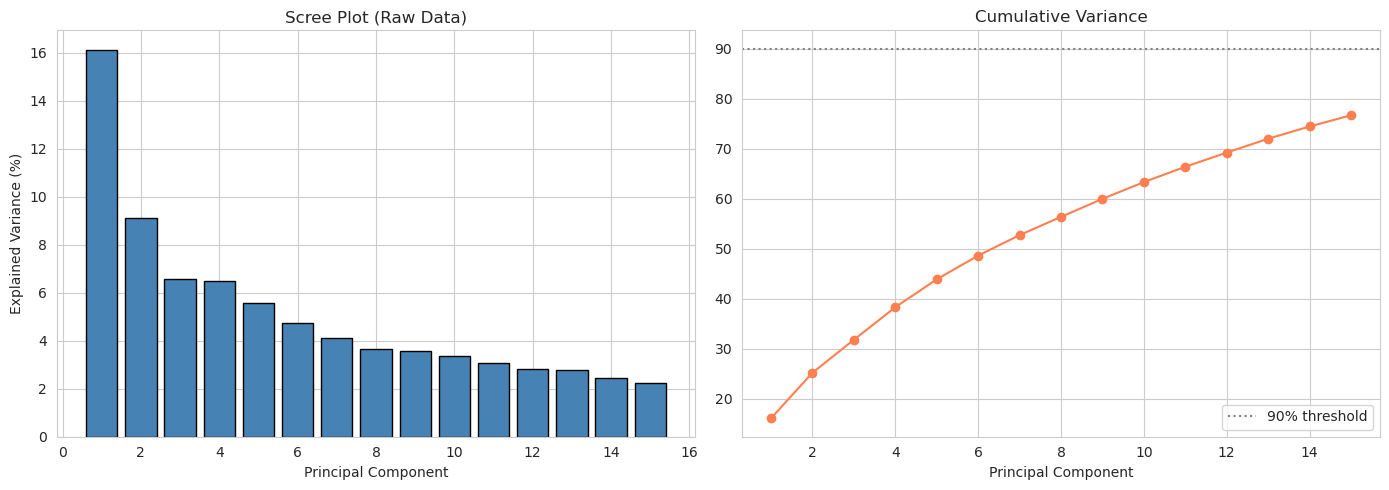

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot explained variance
n_components_show = min(15, len(explained_variance))
axes[0].bar(range(1, n_components_show + 1), explained_variance[:n_components_show] * 100, 
        color='steelblue', edgecolor='black')
axes[0].set_title(f"Scree Plot ({'Standardized' if USE_STANDARDIZED_DATA else 'Raw'} Data)")
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')

# Plot cumulative variance
axes[1].plot(range(1, n_components_show + 1), cumulative_variance[:n_components_show] * 100, 
         'o-', color='coral')
axes[1].axhline(y=90, color='gray', linestyle=':', label='90% threshold')
axes[1].set_title('Cumulative Variance')
axes[1].set_xlabel('Principal Component')
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Temporal Patterns (PC Scores over Time)

**⚠️ Note on Missing Chronological Data:**
There will be missing years in the time series (e.g., 1981, 1983 for Summer) due to strict representative month filtering upstream in Stage 1.5. These years were dropped because sampling did not occur during the designated target month (e.g. July) for that specific year.


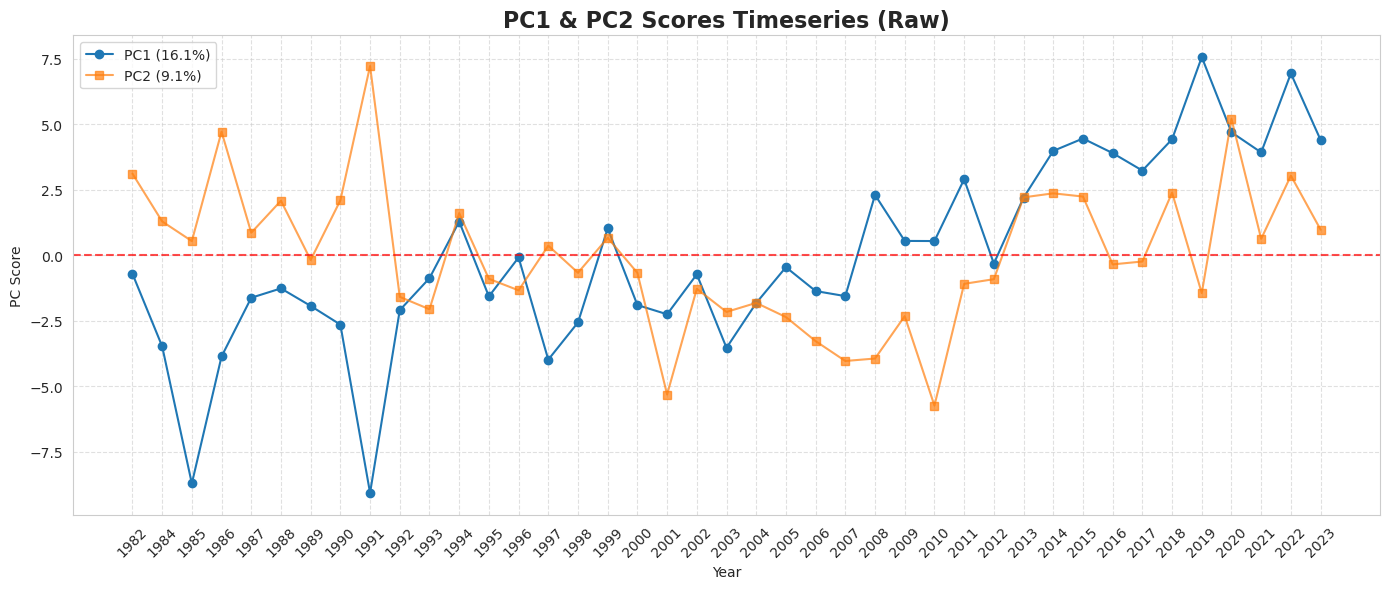

In [10]:
# Plot the temporal evolution of the first 3 PCs
plt.figure(figsize=(14, 6))

# PC1
plt.plot(scores_df.index, scores_df['PC1'], label=f'PC1 ({explained_variance[0]*100:.1f}%)', marker='o')
# PC2
plt.plot(scores_df.index, scores_df['PC2'], label=f'PC2 ({explained_variance[1]*100:.1f}%)', marker='s', alpha=0.7)

plt.axhline(y=0, color='red', linestyle='--', alpha=0.7)
plt.title(f"PC1 & PC2 Scores Timeseries ({'Standardized' if USE_STANDARDIZED_DATA else 'Raw'})", fontsize=16, fontweight='bold')
plt.xlabel("Year")
plt.ylabel("PC Score")
plt.xticks(scores_df.index[::1], rotation=45) # Show every 2nd year labels
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

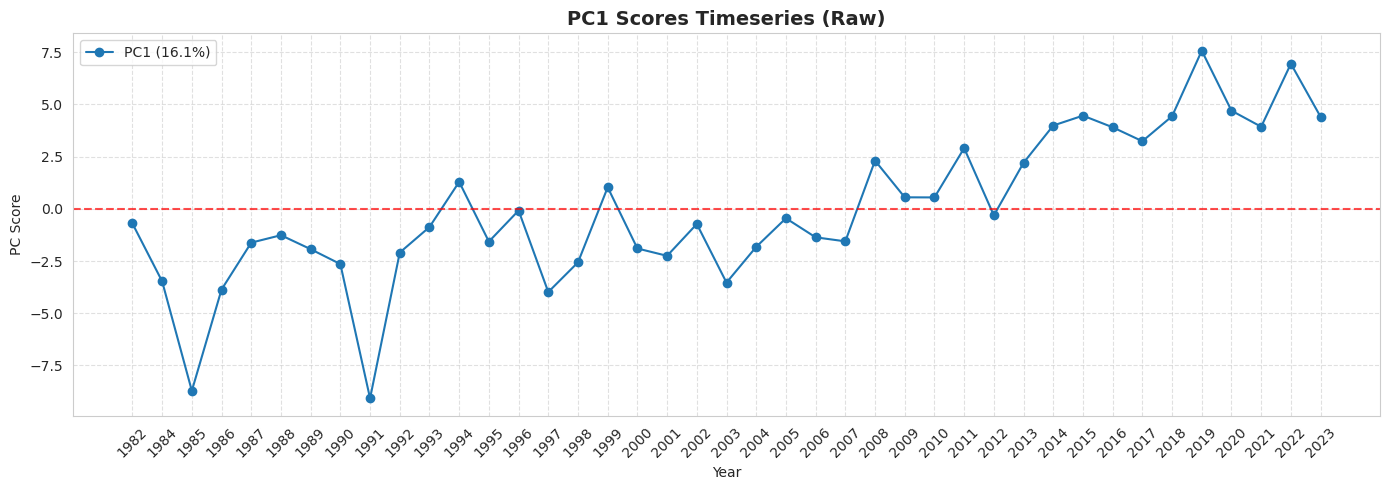

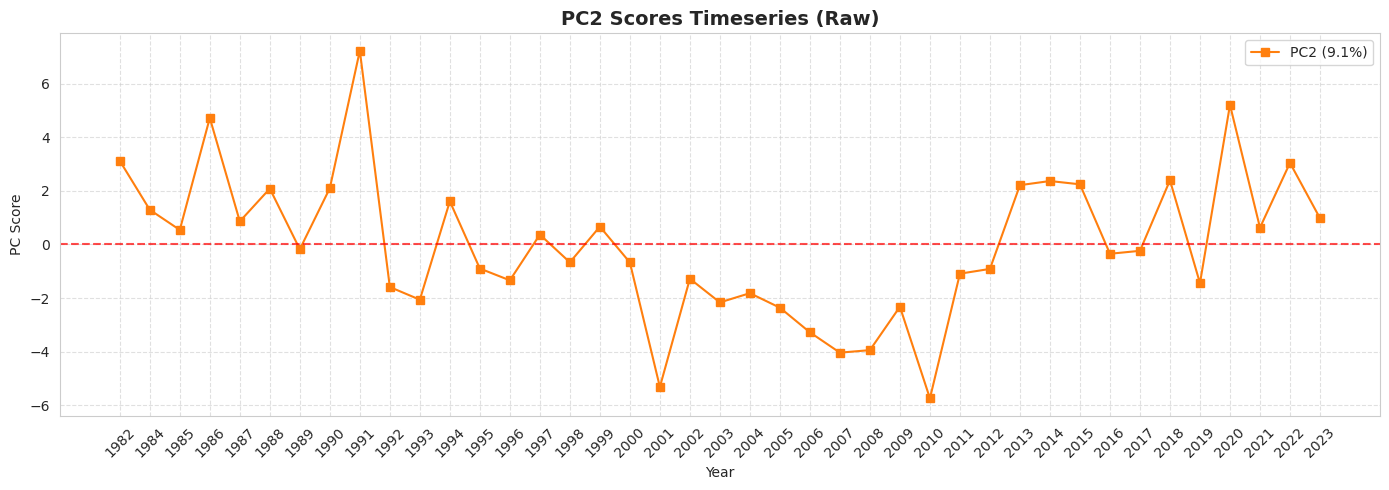

In [11]:
# --- Figure 1: PC1 Scores ---
plt.figure(figsize=(14, 5))
plt.plot(scores_df.index, scores_df['PC1'], 
         label=f'PC1 ({explained_variance[0]*100:.1f}%)', 
         color='tab:blue', marker='o')
plt.axhline(y=0, color='red', linestyle='--', alpha=0.7)
plt.title(f"PC1 Scores Timeseries ({'Standardized' if USE_STANDARDIZED_DATA else 'Raw'})", 
          fontsize=14, fontweight='bold')
plt.xlabel("Year")
plt.ylabel("PC Score")
plt.xticks(scores_df.index[::1], rotation=45) 
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# --- Figure 2: PC2 Scores ---
plt.figure(figsize=(14, 5))
plt.plot(scores_df.index, scores_df['PC2'], 
         label=f'PC2 ({explained_variance[1]*100:.1f}%)', 
         color='tab:orange', marker='s')
plt.axhline(y=0, color='red', linestyle='--', alpha=0.7)
plt.title(f"PC2 Scores Timeseries ({'Standardized' if USE_STANDARDIZED_DATA else 'Raw'})", 
          fontsize=14, fontweight='bold')
plt.xlabel("Year")
plt.ylabel("PC Score")
plt.xticks(scores_df.index[::1], rotation=45) 
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

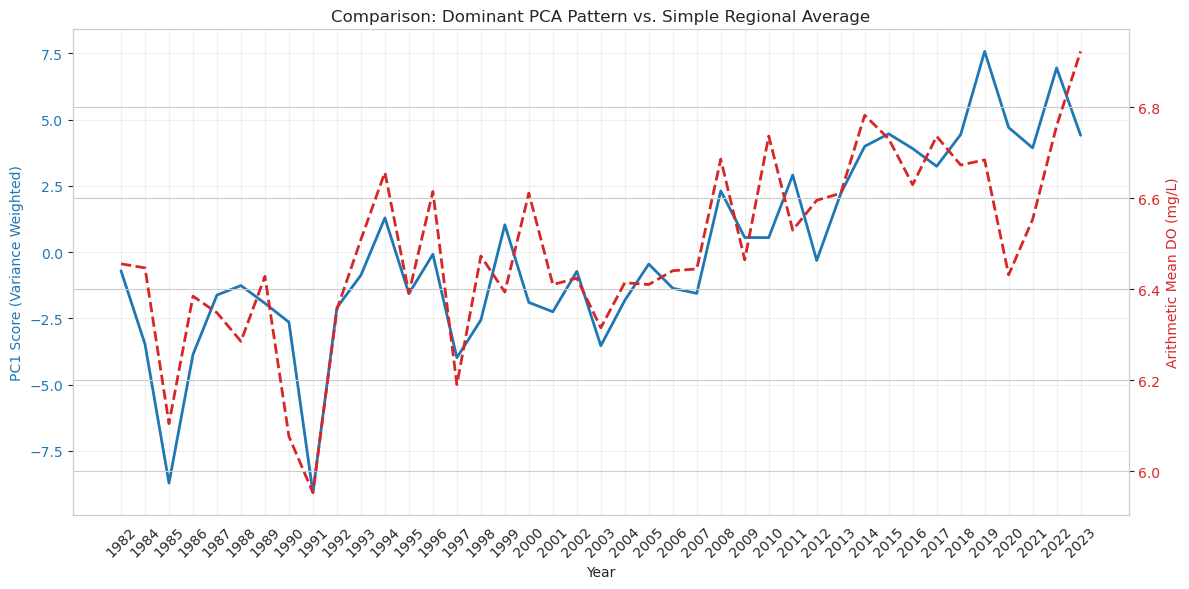

Correlation between PC1 Score and Arithmetic Mean: 0.8131


In [12]:
# --- Sanity Check: PC Scores vs. Arithmetic Mean ---

# 1. Calculate the Simple Arithmetic Mean across all stations for each year
# (axis=1 because pca_input_data rows are years, columns are stations)
annual_mean_do = pca_input_data.mean(axis=1)

# 2. Plotting
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot PC1 Score (Primary Axis)
color = 'tab:blue'
ax1.set_xlabel('Year')
ax1.set_ylabel('PC1 Score (Variance Weighted)', color=color)
ax1.plot(scores_df.index, scores_df['PC1'], color=color, label='PC1 Score', linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)
plt.xticks(rotation=45)
ax1.grid(True, alpha=0.3)

# Create a second y-axis for the Mean DO
ax2 = ax1.twinx() 
color = 'tab:red'
ax2.set_ylabel('Arithmetic Mean DO (mg/L)', color=color)  
ax2.plot(scores_df.index, annual_mean_do, color=color, linestyle='--', label='Arithmetic Mean', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)

# Title and Layout
plt.title('Comparison: Dominant PCA Pattern vs. Simple Regional Average')
fig.tight_layout()
plt.show()

# Correlation Check
correlation = np.corrcoef(scores_df['PC1'], annual_mean_do)[0, 1]
print(f"Correlation between PC1 Score and Arithmetic Mean: {correlation:.4f}")

## 6. Spatial Patterns (PC Loadings)

The loadings show how each station contributes to each principal component.

In [13]:
# Get loadings (components)
loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_ready_df.index,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

print(f"Loadings shape: {loadings.shape}\n")

# --- PC1 Summary ---
pc1_top10_high = loadings['PC1'].nlargest(10).reset_index()
pc1_top10_high.columns = ['Station_ID', 'PC1_Loading']
pc1_top10_high['Rank'] = range(1, 11)
pc1_top10_high['Type'] = 'Highest'

pc1_top10_low = loadings['PC1'].nsmallest(10).reset_index()
pc1_top10_low.columns = ['Station_ID', 'PC1_Loading']
pc1_top10_low['Rank'] = range(1, 11)
pc1_top10_low['Type'] = 'Lowest'

pc1_summary = pd.concat([pc1_top10_high, pc1_top10_low], ignore_index=True)
pc1_summary = pc1_summary[['Rank', 'Type', 'Station_ID', 'PC1_Loading']]

# --- PC2 Summary ---
pc2_top10_high = loadings['PC2'].nlargest(10).reset_index()
pc2_top10_high.columns = ['Station_ID', 'PC2_Loading']
pc2_top10_high['Rank'] = range(1, 11)
pc2_top10_high['Type'] = 'Highest'

pc2_top10_low = loadings['PC2'].nsmallest(10).reset_index()
pc2_top10_low.columns = ['Station_ID', 'PC2_Loading']
pc2_top10_low['Rank'] = range(1, 11)
pc2_top10_low['Type'] = 'Lowest'

pc2_summary = pd.concat([pc2_top10_high, pc2_top10_low], ignore_index=True)
pc2_summary = pc2_summary[['Rank', 'Type', 'Station_ID', 'PC2_Loading']]

# --- Display Tables ---
print("=" * 50)
print("PC1: Top 10 Highest & Lowest Loading Stations")
print("=" * 50)
display(pc1_summary.style.format({'PC1_Loading': '{:.4f}'}).hide(axis='index'))

print("\n" + "=" * 50)
print("PC2: Top 10 Highest & Lowest Loading Stations")
print("=" * 50)
display(pc2_summary.style.format({'PC2_Loading': '{:.4f}'}).hide(axis='index'))

Loadings shape: (124, 41)

PC1: Top 10 Highest & Lowest Loading Stations


Rank,Type,Station_ID,PC1_Loading
1,Highest,00040617,0.3375
2,Highest,00040620,0.3263
3,Highest,00040636,0.3098
4,Highest,00028153,0.2461
5,Highest,00028169,0.2455
6,Highest,00040632,0.2343
7,Highest,00028143,0.2042
8,Highest,00044594,0.1952
9,Highest,00028168,0.1845
10,Highest,00028150,0.1800



PC2: Top 10 Highest & Lowest Loading Stations


Rank,Type,Station_ID,PC2_Loading
1,Highest,00002823,0.4390
2,Highest,00040632,0.1913
3,Highest,00002811,0.1505
4,Highest,00040620,0.1488
5,Highest,00000272,0.1111
6,Highest,00044531,0.1031
7,Highest,00040636,0.0986
8,Highest,00040714,0.0982
9,Highest,00002725,0.0976
10,Highest,00040715,0.0814


## Stations Eigenvectors

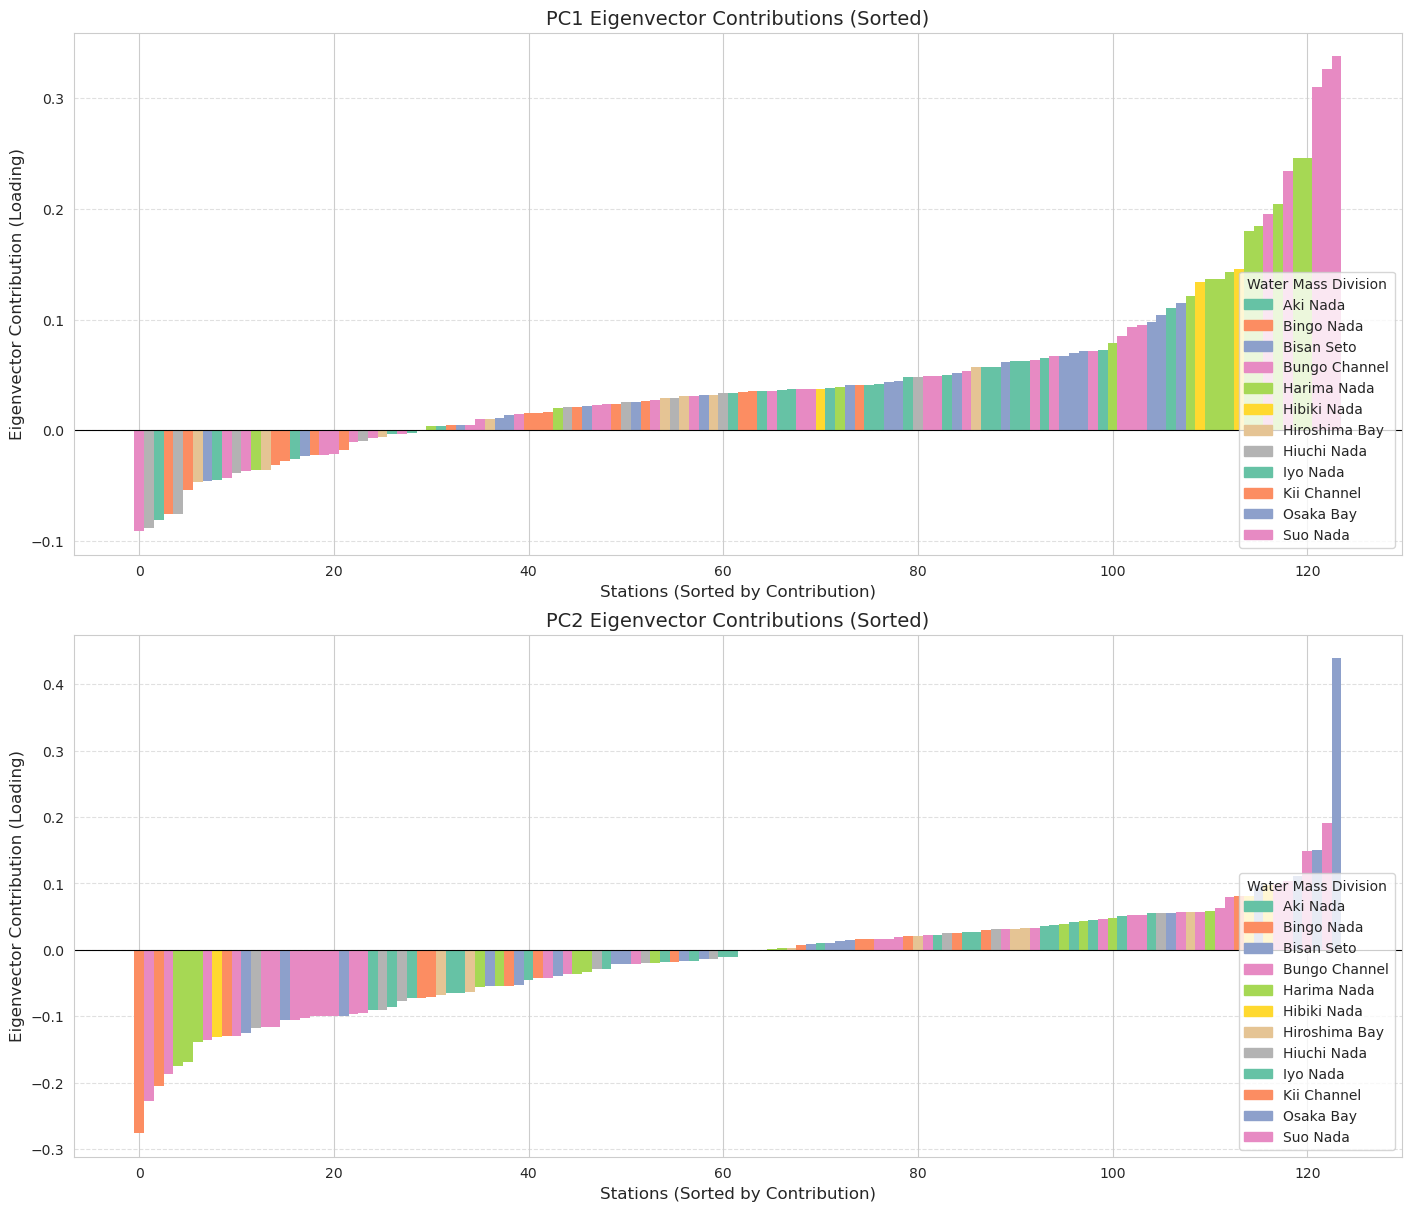

In [14]:
# 6. Eigenvector Contribution Analysis (PC1 & PC2) by Station

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pandas as pd

# 1. Load Station Division Data
merged_gdf_path = ProjectPaths.PROCESSED_DATA_DIR / "merged_gdf.feather"
if merged_gdf_path.exists():
    merged_gdf = pd.read_feather(merged_gdf_path)
    
    # Check if 'Station' column exists, otherwise use 'zettaicode'
    station_col = 'Station' if 'Station' in merged_gdf.columns else 'zettaicode'
    
    # Ensure Station ID is treated as zfilled string to match PCA index
    merged_gdf[station_col] = merged_gdf[station_col].astype(str).str.zfill(8)
    
    # Create mapping dictionary: Station ID -> Division
    division_map = merged_gdf.drop_duplicates(station_col).set_index(station_col)['division'].to_dict()
else:
    print("Warning: merged_gdf.feather not found. Divisions will be unknown.")
    division_map = {}

# 2. Extract Eigenvectors (Loadings) for PC1 and PC2
# Use pca_ready_df.index because in your PCA prep, features (stations) were rows of original df
loadings_df = pd.DataFrame(
    pca.components_[:2, :].T, 
    columns=['PC1', 'PC2'], 
    index=pca_ready_df.index  # CORRECTED: Use .index (stations) instead of .columns (years)
)

# 3. Add Division Info
loadings_df['division'] = loadings_df.index.map(division_map).fillna('Unknown')

# 4. Define Color Palette for Divisions
unique_divisions = sorted(loadings_df['division'].unique())
palette = sns.color_palette("Set2", len(unique_divisions))
color_map = dict(zip(unique_divisions, palette))

# 5. Plotting Function
def plot_eigenvector_contribution(ax, component, title):
    # Sort data by the specific component's loading value
    data = loadings_df.sort_values(by=component)
    
    # Map colors
    colors = [color_map[d] for d in data['division']]
    
    # Create Bar Plot
    ax.bar(range(len(data)), data[component], color=colors, width=1.0, edgecolor='none')
    
    # Styling
    ax.set_title(title, fontsize=14)
    ax.set_ylabel('Eigenvector Contribution (Loading)', fontsize=12)
    ax.set_xlabel('Stations (Sorted by Contribution)', fontsize=12)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='-')
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    
    # Create Custom Legend
    legend_patches = [mpatches.Patch(color=color_map[d], label=d) for d in unique_divisions]
    ax.legend(handles=legend_patches, title='Water Mass Division', loc='lower right', fontsize=10)

# Create Subplots
fig, axes = plt.subplots(2, 1, figsize=(14, 12), constrained_layout=True)

plot_eigenvector_contribution(axes[0], 'PC1', 'PC1 Eigenvector Contributions (Sorted)')
plot_eigenvector_contribution(axes[1], 'PC2', 'PC2 Eigenvector Contributions (Sorted)')

plt.show()

## Plot all stations across PC1 and PC2

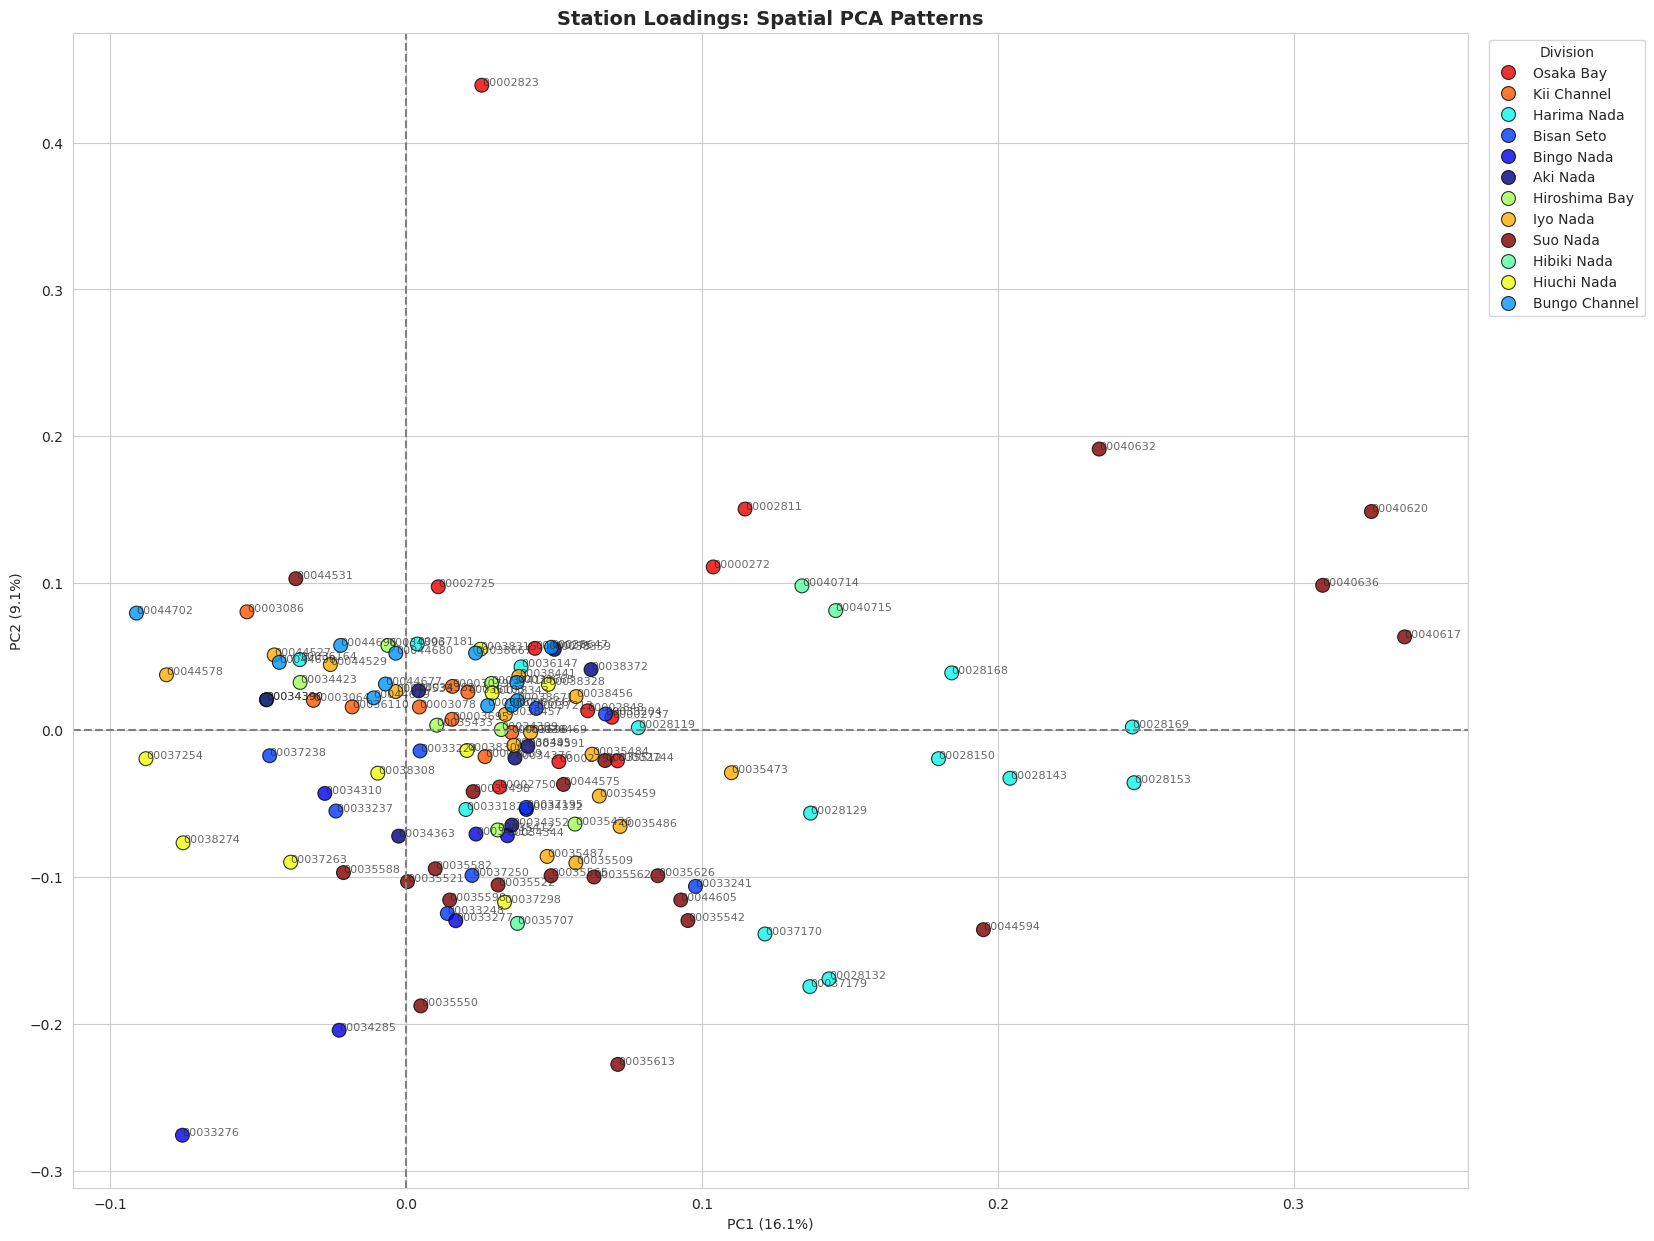

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib

# 1. Prepare Data
# Transpose if needed: We want Stations as Rows (approx ~120 rows), not Columns
plot_data = loadings_df.T.copy() if loadings_df.shape[1] > loadings_df.shape[0] else loadings_df.copy()

# Standardize columns to PC1, PC2...
plot_data.columns = [f"PC{i+1}" for i in range(plot_data.shape[1])]
plot_data.index.name = 'zettaicode'
plot_data = plot_data.reset_index()

# 2. Add Divisions from Metadata
try:
    meta_path = ProjectPaths.PROCESSED_DATA_DIR / 'merged_gdf_saisuipoin_cleaned.feather'
    meta = pd.read_feather(meta_path)[['zettaicode', 'division']].drop_duplicates()
    # Merge ensuring strings match
    plot_data['zettaicode'] = plot_data['zettaicode'].astype(str)
    meta['zettaicode'] = meta['zettaicode'].astype(str)
    plot_data = plot_data.merge(meta, on='zettaicode', how='left').fillna({'division': 'Unknown'})
except Exception as e:
    print(f"Metadata error: {e}")
    plot_data['division'] = 'Unknown'

# 3. Plot
plt.figure(figsize=(18, 15))

# Create distinct colors for divisions
divs = sorted(plot_data['division'].unique())
cmap = matplotlib.colormaps['jet'] if hasattr(matplotlib, 'colormaps') else plt.cm.get_cmap('jet')
colors = {d: cmap(i) for d, i in zip(divs, np.linspace(0, 1, len(divs)))}

sns.scatterplot(data=plot_data, x='PC1', y='PC2', hue='division', palette=colors, s=100, edgecolor='k', alpha=0.8)

# Annotate stations
for _, row in plot_data.iterrows():
    plt.text(row['PC1'], row['PC2'], str(row['zettaicode']), fontsize=8, alpha=0.7)

# Formatting
v1, v2 = explained_variance[0]*100, explained_variance[1]*100
plt.xlabel(f"PC1 ({v1:.1f}%)"); plt.ylabel(f"PC2 ({v2:.1f}%)")
plt.axhline(0, c='gray', ls='--'); plt.axvline(0, c='gray', ls='--')
plt.title("Station Loadings: Spatial PCA Patterns", fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', title='Division')
plt.show()

## Plot the station's eigenvector contribution

Merge Result: 124 stations matched out of 124 PCA stations.


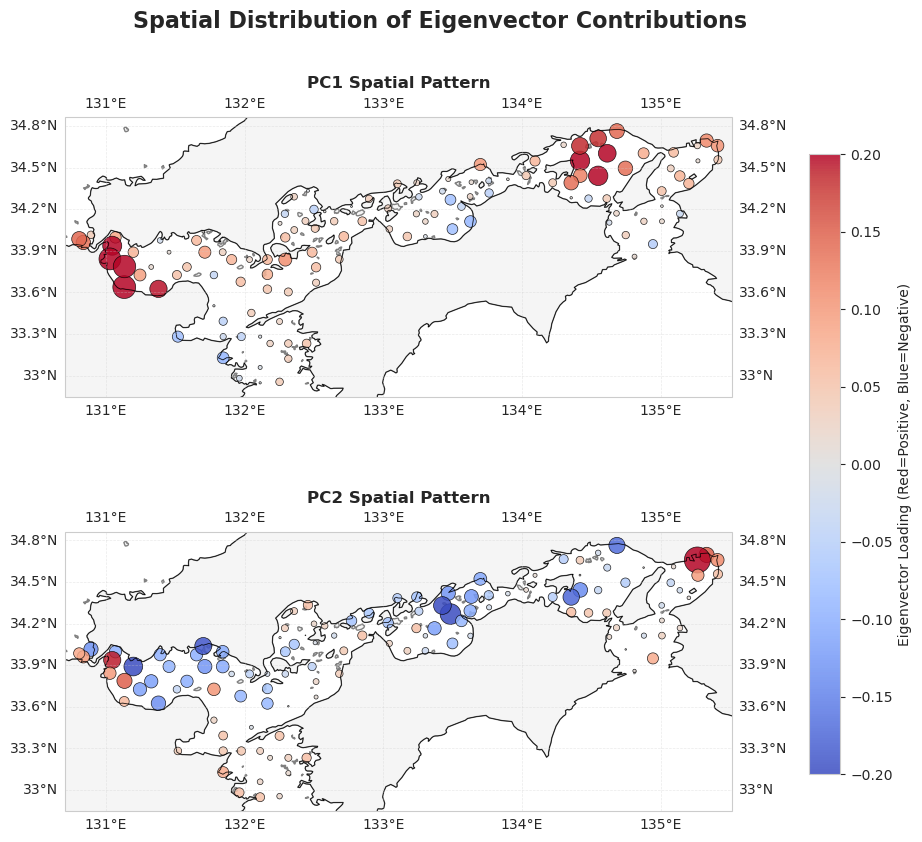

In [16]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1. Get Eigenvectors (Loadings)
pc1_loadings = pca.components_[0]
pc2_loadings = pca.components_[1]

# 2. Get Station Coordinates
gdf_path = ProjectPaths.PROCESSED_DATA_DIR / "merged_gdf.feather"
gdf = gpd.read_feather(gdf_path)

# 3. Create loadings DataFrame
station_ids = pca_ready_df.index.tolist()

loadings_df = pd.DataFrame({
    'zettaicode': station_ids,
    'PC1_Loading': pc1_loadings,
    'PC2_Loading': pc2_loadings
})

gdf_unique_stations = gdf.drop_duplicates(subset='zettaicode')[['zettaicode', 'geometry']].copy()
loadings_df['zettaicode'] = loadings_df['zettaicode'].astype(str)
gdf_unique_stations['zettaicode'] = gdf_unique_stations['zettaicode'].astype(str)
loadings_map_data = gdf_unique_stations.merge(loadings_df, on='zettaicode', how='inner')

print(f"Merge Result: {len(loadings_map_data)} stations matched out of {len(station_ids)} PCA stations.")

# 4. Dynamically calculate figure height to match Cartopy's enforced aspect ratio
n_rows, n_cols = 2, 1
pad = 0.1
min_lon, min_lat, max_lon, max_lat = loadings_map_data.total_bounds
extent = [min_lon - pad, max_lon + pad, min_lat - pad, max_lat + pad]

aspect_ratio = (extent[3] - extent[2]) / (extent[1] - extent[0])
fig_width = 10
width_per_subplot = fig_width / n_cols
height_per_subplot = (width_per_subplot * aspect_ratio) + 0.3  # +0.3 buffer for subplot titles
# Add extra buffer for the suptitle and colorbar
fig_height = (height_per_subplot * n_rows) + 1.0

# 5. Plotting (Vertical Stack)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(fig_width, fig_height),
                         subplot_kw={'projection': ccrs.PlateCarree()})

fig.suptitle('Spatial Distribution of Eigenvector Contributions', fontsize=16, fontweight='bold')

components = [('PC1_Loading', 'PC1'), ('PC2_Loading', 'PC2')]

for ax, (col, title) in zip(axes, components):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor='whitesmoke', edgecolor='gray')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4, linewidth=0.5)

    sc = ax.scatter(
        loadings_map_data.geometry.x,
        loadings_map_data.geometry.y,
        c=loadings_map_data[col],
        s=loadings_map_data[col].abs() * 800,
        cmap='coolwarm',
        edgecolor='k',
        linewidth=0.5,
        alpha=0.85,
        transform=ccrs.PlateCarree(),
        vmin=-0.2, vmax=0.2
    )
    ax.set_title(f'{title} Spatial Pattern', fontsize=12, fontweight='bold')

# Use subplots_adjust instead of tight_layout (which struggles with Cartopy axes)
plt.subplots_adjust(hspace=0.05, top=0.93, bottom=0.12)

# Colorbar shifted further right
cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), orientation='vertical', fraction=0.04, pad=0.1)
cbar.set_label('Eigenvector Loading (Red=Positive, Blue=Negative)')

plt.show()


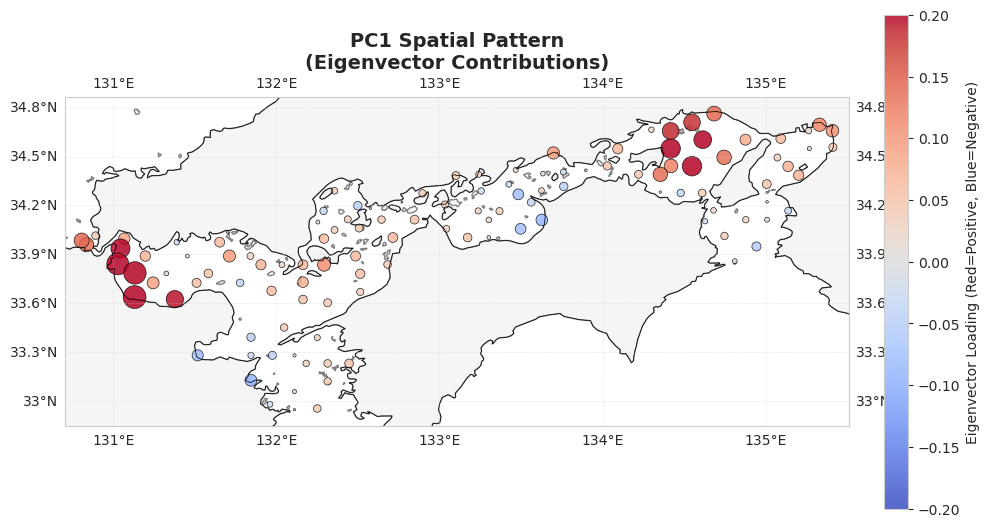

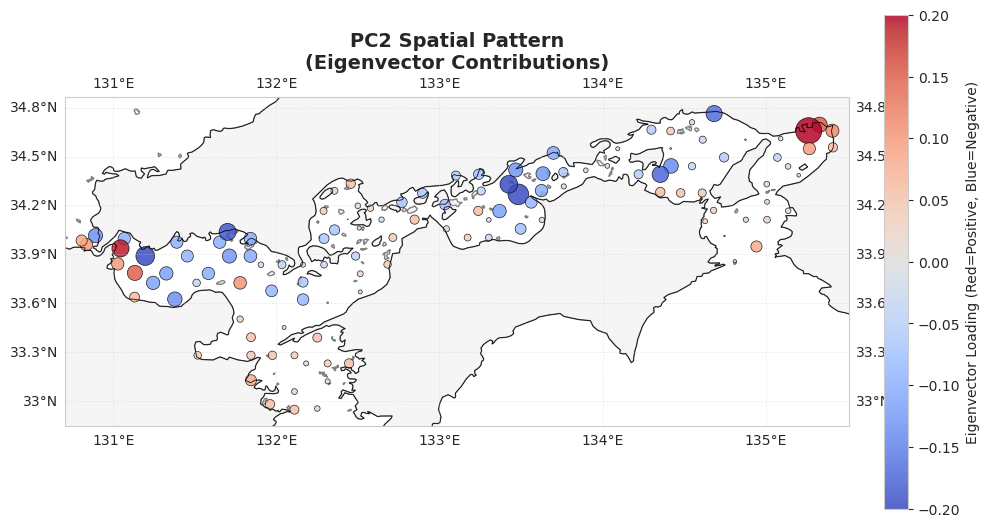

In [17]:
# 1. Calculation for Figure Dimensions (Maintaining Aspect Ratio)
pad = 0.1
min_lon, min_lat, max_lon, max_lat = loadings_map_data.total_bounds
extent = [min_lon - pad, max_lon + pad, min_lat - pad, max_lat + pad]

aspect_ratio = (extent[3] - extent[2]) / (extent[1] - extent[0])
fig_width = 10
# Calculate height for a single figure based on the geographical aspect ratio
single_fig_height = (fig_width * aspect_ratio) + 1.2  # Buffer for title and labels

components = [('PC1_Loading', 'PC1'), ('PC2_Loading', 'PC2')]

# 2. Iterate and create two separate figures
for col, title in components:
    fig = plt.figure(figsize=(fig_width, single_fig_height))
    ax = plt.axes(projection=ccrs.PlateCarree())
    
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor='whitesmoke', edgecolor='gray')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4, linewidth=0.5)

    sc = ax.scatter(
        loadings_map_data.geometry.x,
        loadings_map_data.geometry.y,
        c=loadings_map_data[col],
        s=loadings_map_data[col].abs() * 800,
        cmap='coolwarm',
        edgecolor='k',
        linewidth=0.5,
        alpha=0.85,
        transform=ccrs.PlateCarree(),
        vmin=-0.2, vmax=0.2
    )
    
    ax.set_title(f'{title} Spatial Pattern\n(Eigenvector Contributions)', 
                 fontsize=14, fontweight='bold')

    # Add colorbar for each individual figure
    cbar = plt.colorbar(sc, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
    cbar.set_label('Eigenvector Loading (Red=Positive, Blue=Negative)')
    
    plt.tight_layout()
    plt.show()

## 7. Summary Statistics

In [18]:
# Determine number of PCs needed for 80% and 90% variance
n_80 = np.argmax(cumulative_variance >= 0.80) + 1
n_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("=" * 50)
print("PCA ANALYSIS SUMMARY")
print("=" * 50)
print(f"Total stations analyzed: {len(pca_ready_df)}")
print(f"Total years: {len(pca_ready_df.columns)}")
print(f"\nVariance explained by PC1: {explained_variance[0]*100:.2f}%")
print(f"Variance explained by PC2: {explained_variance[1]*100:.2f}%")
print(f"Variance explained by PC3: {explained_variance[2]*100:.2f}%")
print(f"\nComponents needed for 80% variance: {n_80}")
print(f"Components needed for 90% variance: {n_90}")
print("=" * 50)

PCA ANALYSIS SUMMARY
Total stations analyzed: 124
Total years: 41

Variance explained by PC1: 16.13%
Variance explained by PC2: 9.11%
Variance explained by PC3: 6.59%

Components needed for 80% variance: 17
Components needed for 90% variance: 24


# Interpretation

The current hypothesis is that the stations with a high decorrelation scale will have an opposite yearly trend compared to the stations with a low decorrelation scale. Let's test this.

In [19]:
# Merge PCA loadings with decorrelation scale data
# First, ensure loadings dataframe has station IDs as index
loadings_analysis = loadings[['PC1', 'PC2', 'PC3']].copy()
loadings_analysis.index.name = 'Station_ID'

# Load decorrelation data if not already loaded
decorrelation_df = pd.read_csv(Path(subset_dir) / "stations_decorrelation_scale.csv")
decorrelation_df['Station_ID'] = decorrelation_df['Station_ID'].astype(str).str.zfill(8)
decorrelation_df = decorrelation_df.set_index('Station_ID')

# Merge
analysis_df = loadings_analysis.join(decorrelation_df['Decorrelation_Scale_km'], how='inner')
print(f"Stations with both PCA loadings and decorrelation scale: {len(analysis_df)}")
analysis_df.head()

Stations with both PCA loadings and decorrelation scale: 124


,PC1,PC2,PC3,Decorrelation_Scale_km
Station_ID,,,,
00000272,0.103866,0.111102,-0.121960,0.459884
00000275,0.043625,0.055679,-0.188458,9.509381
00002725,0.010962,0.097602,-0.153041,8.890848
00002737,0.069656,0.008763,0.119226,4.851579
00002744,0.071522,-0.020887,0.008511,5.398100


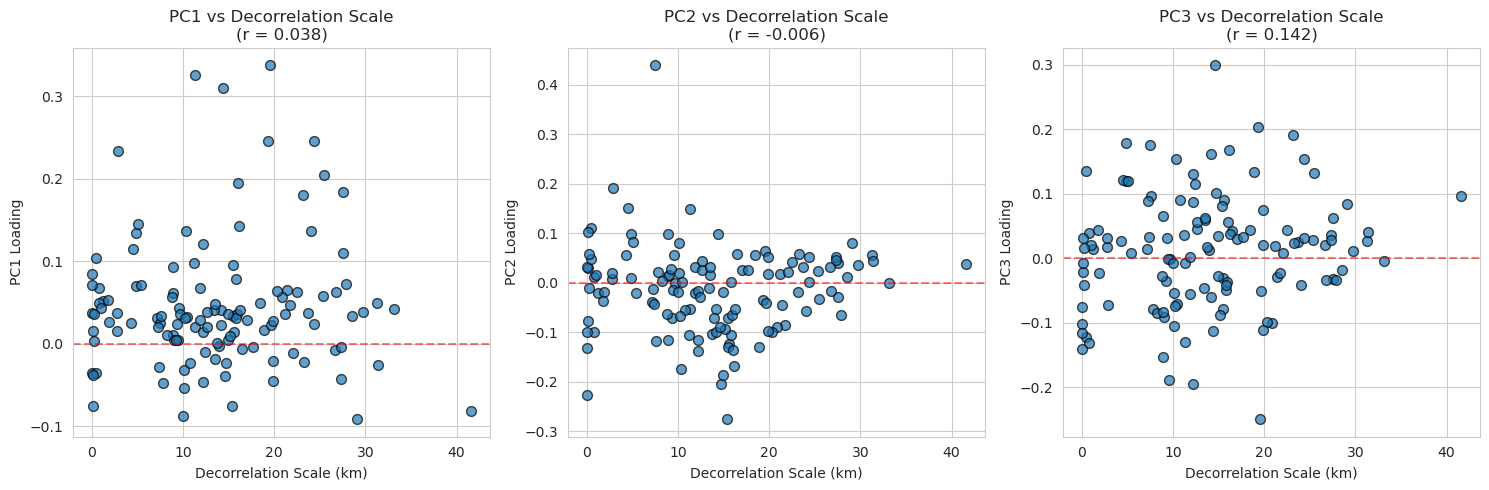

In [20]:
# Scatter plots: Decorrelation Scale vs PC Loadings
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, ax in enumerate(axes):
    pc_col = f'PC{i+1}'
    
    ax.scatter(analysis_df['Decorrelation_Scale_km'], analysis_df[pc_col], 
               alpha=0.7, edgecolor='black', s=50)
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.5)
    
    # Calculate correlation
    corr = analysis_df['Decorrelation_Scale_km'].corr(analysis_df[pc_col])
    ax.set_xlabel('Decorrelation Scale (km)')
    ax.set_ylabel(f'{pc_col} Loading')
    ax.set_title(f'{pc_col} vs Decorrelation Scale\n(r = {corr:.3f})')
    
plt.tight_layout()
plt.show()

In [21]:
# Divide stations into extreme groups: bottom 25% vs top 25% of decorrelation scale
# This focuses on stations at the extremes for a more meaningful comparison
q25 = analysis_df['Decorrelation_Scale_km'].quantile(0.25)
q75 = analysis_df['Decorrelation_Scale_km'].quantile(0.75)
print(f"25th percentile decorrelation scale: {q25:.2f} km")
print(f"75th percentile decorrelation scale: {q75:.2f} km")

# Create groups - only include extreme stations (bottom 25% and top 25%)
def assign_extreme_group(val):
    if val <= q25:
        return 'Low (≤ 25th pctl)'
    elif val >= q75:
        return 'High (≥ 75th pctl)'
    else:
        return 'Middle (excluded)'

analysis_df['Scale_Group'] = analysis_df['Decorrelation_Scale_km'].apply(assign_extreme_group)

# Filter to only extreme groups for comparison
extreme_df = analysis_df[analysis_df['Scale_Group'] != 'Middle (excluded)'].copy()
print(f"\nNumber of stations in Low group (≤ 25th pctl): {len(extreme_df[extreme_df['Scale_Group'] == 'Low (≤ 25th pctl)'])}")
print(f"Number of stations in High group (≥ 75th pctl): {len(extreme_df[extreme_df['Scale_Group'] == 'High (≥ 75th pctl)'])}")

# Compare mean loadings between extreme groups
group_stats = extreme_df.groupby('Scale_Group')[['PC1', 'PC2', 'PC3']].agg(['mean', 'std'])
print("\n=== Mean PC Loadings by Decorrelation Scale Group (Extreme Quartiles) ===")
print(group_stats)

25th percentile decorrelation scale: 7.73 km
75th percentile decorrelation scale: 19.84 km

Number of stations in Low group (≤ 25th pctl): 31
Number of stations in High group (≥ 75th pctl): 31

=== Mean PC Loadings by Decorrelation Scale Group (Extreme Quartiles) ===
                         PC1                 PC2                 PC3          
                        mean       std      mean       std      mean       std
Scale_Group                                                                   
High (≥ 75th pctl)  0.047152  0.079794  0.003036  0.052050  0.019698  0.068514
Low (≤ 25th pctl)   0.044985  0.060954  0.016328  0.116788  0.015404  0.088144


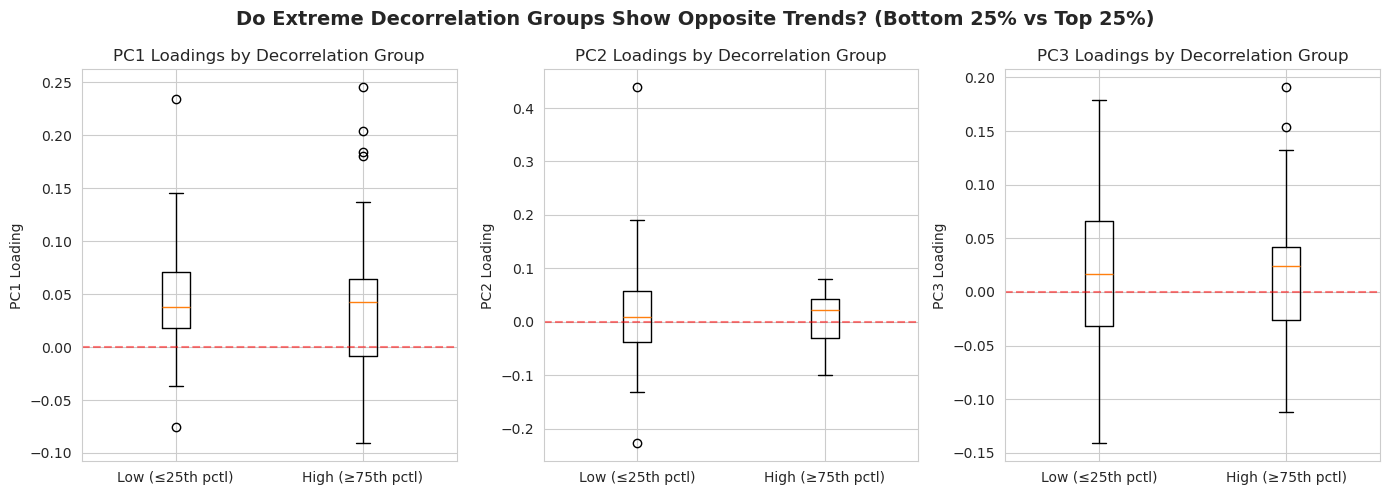

In [22]:
# Box plot comparison of loadings by extreme groups (quartiles)
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for i, ax in enumerate(axes):
    pc_col = f'PC{i+1}'
    
    # Separate data by extreme group (using extreme_df instead of analysis_df)
    high_group = extreme_df[extreme_df['Scale_Group'] == 'High (≥ 75th pctl)'][pc_col]
    low_group = extreme_df[extreme_df['Scale_Group'] == 'Low (≤ 25th pctl)'][pc_col]
    
    ax.boxplot([low_group, high_group], tick_labels=['Low (≤25th pctl)', 'High (≥75th pctl)'])
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.5)
    ax.set_ylabel(f'{pc_col} Loading')
    ax.set_title(f'{pc_col} Loadings by Decorrelation Group')
    
plt.suptitle('Do Extreme Decorrelation Groups Show Opposite Trends? (Bottom 25% vs Top 25%)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [23]:
from scipy import stats

# T-test to check if extreme groups have significantly different loadings
print("=== T-Test Results (Extreme Decorrelation Scale Groups: Top 25% vs Bottom 25%) ===\n")

for i in range(3):
    pc_col = f'PC{i+1}'
    
    # Use extreme_df which only contains stations in top 25% and bottom 25%
    high_group = extreme_df[extreme_df['Scale_Group'] == 'High (≥ 75th pctl)'][pc_col]
    low_group = extreme_df[extreme_df['Scale_Group'] == 'Low (≤ 25th pctl)'][pc_col]
    
    t_stat, p_value = stats.ttest_ind(high_group, low_group)
    
    # Check if opposite signs (opposite trends)
    mean_high = high_group.mean()
    mean_low = low_group.mean()
    opposite = (mean_high > 0 and mean_low < 0) or (mean_high < 0 and mean_low > 0)
    
    print(f"{pc_col}:")
    print(f"  Mean (High Scale, ≥75th pctl): {mean_high:.4f}")
    print(f"  Mean (Low Scale, ≤25th pctl):  {mean_low:.4f}")
    print(f"  Opposite signs?    {'YES ✓' if opposite else 'NO'}")
    print(f"  T-statistic: {t_stat:.3f}, p-value: {p_value:.4f}")
    print(f"  Significant (p<0.05)? {'YES ✓' if p_value < 0.05 else 'NO'}")
    print()

=== T-Test Results (Extreme Decorrelation Scale Groups: Top 25% vs Bottom 25%) ===

PC1:
  Mean (High Scale, ≥75th pctl): 0.0472
  Mean (Low Scale, ≤25th pctl):  0.0450
  Opposite signs?    NO
  T-statistic: 0.120, p-value: 0.9048
  Significant (p<0.05)? NO

PC2:
  Mean (High Scale, ≥75th pctl): 0.0030
  Mean (Low Scale, ≤25th pctl):  0.0163
  Opposite signs?    NO
  T-statistic: -0.579, p-value: 0.5649
  Significant (p<0.05)? NO

PC3:
  Mean (High Scale, ≥75th pctl): 0.0197
  Mean (Low Scale, ≤25th pctl):  0.0154
  Opposite signs?    NO
  T-statistic: 0.214, p-value: 0.8311
  Significant (p<0.05)? NO



The T-test results doesn't show a significant result between the two groups. From these results it seems that the hypothesis is incorrect. This might suggest that there are other causing factors other than DO.

In [24]:
# --- Save PCA Results to Subset Directory ---
from pathlib import Path
subset_path = Path(subset_dir)

# 1. Save Temporal Scores (PC values for each year)
scores_path = subset_path / "pca_scores.csv"
scores_df.to_csv(scores_path)
print(f"Saved Scores to: {scores_path}")

# 2. Save Spatial Loadings (Contribution of each station to PCs)
loadings_path = subset_path / "pca_loadings.csv"
loadings_df.to_csv(loadings_path)
print(f"Saved Loadings to: {loadings_path}")

# 3. Save Variance Explained Stats
variance_df = pd.DataFrame({
    'PC': [f"PC{i+1}" for i in range(len(explained_variance))],
    'Explained_Variance': explained_variance,
    'Cumulative_Variance': cumulative_variance
})
variance_path = subset_path / "pca_variance.csv"
variance_df.to_csv(variance_path, index=False)
print(f"Saved Variance Stats to: {variance_path}")

Saved Scores to: /home/reyha/SIS_Analysis_WSL/data/processed/seasonal/summer_bottom/pca_scores.csv
Saved Loadings to: /home/reyha/SIS_Analysis_WSL/data/processed/seasonal/summer_bottom/pca_loadings.csv
Saved Variance Stats to: /home/reyha/SIS_Analysis_WSL/data/processed/seasonal/summer_bottom/pca_variance.csv
